In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
dataset_path = r"C:\Music_Genre_Classification\Dataset\features_30_sec.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1000, 60)


,filename,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues.00000.wav,661794,0.350088,0.088757,0.130228,0.002827,1784.165850,129774.064525,2002.449060,85882.761315,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,blues.00001.wav,661794,0.340914,0.094980,0.095948,0.002373,1530.176679,375850.073649,2039.036516,213843.755497,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,blues.00002.wav,661794,0.363637,0.085275,0.175570,0.002746,1552.811865,156467.643368,1747.702312,76254.192257,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,blues.00003.wav,661794,0.404785,0.093999,0.141093,0.006346,1070.106615,184355.942417,1596.412872,166441.494769,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,blues.00004.wav,661794,0.308526,0.087841,0.091529,0.002303,1835.004266,343399.939274,1748.172116,88445.209036,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues


In [ ]:
print("Columns in Dataset:")
print(df.columns.tolist())

Columns in Dataset:
['filename', 'length', 'chroma_stft_mean', 'chroma_stft_var', 'rms_mean', 'rms_var', 'spectral_centroid_mean', 'spectral_centroid_var', 'spectral_bandwidth_mean', 'spectral_bandwidth_var', 'rolloff_mean', 'rolloff_var', 'zero_crossing_rate_mean', 'zero_crossing_rate_var', 'harmony_mean', 'harmony_var', 'perceptr_mean', 'perceptr_var', 'tempo', 'mfcc1_mean', 'mfcc1_var', 'mfcc2_mean', 'mfcc2_var', 'mfcc3_mean', 'mfcc3_var', 'mfcc4_mean', 'mfcc4_var', 'mfcc5_mean', 'mfcc5_var', 'mfcc6_mean', 'mfcc6_var', 'mfcc7_mean', 'mfcc7_var', 'mfcc8_mean', 'mfcc8_var', 'mfcc9_mean', 'mfcc9_var', 'mfcc10_mean', 'mfcc10_var', 'mfcc11_mean', 'mfcc11_var', 'mfcc12_mean', 'mfcc12_var', 'mfcc13_mean', 'mfcc13_var', 'mfcc14_mean', 'mfcc14_var', 'mfcc15_mean', 'mfcc15_var', 'mfcc16_mean', 'mfcc16_var', 'mfcc17_mean', 'mfcc17_var', 'mfcc18_mean', 'mfcc18_var', 'mfcc19_mean', 'mfcc19_var', 'mfcc20_mean', 'mfcc20_var', 'label']


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   str    
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   float64
 14  harmony_mean             1000 non-nu

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 60 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   str    
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   float64
 14  harmony_mean             1000 non-nu

In [ ]:
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate Filenames:", df['filename'].duplicated().sum())

Duplicate Rows: 0
Duplicate Filenames: 0


In [ ]:
print(df['label'].value_counts())

label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64


In [ ]:
df.describe()

,length,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,spectral_bandwidth_var,rolloff_mean,...,mfcc16_mean,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03,1000.000000,1000.000000,1000.000000,...,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,662030.846000,0.378682,0.086340,0.130930,0.003051,2201.780898,4.696916e+05,2242.541070,137079.155165,4571.549304,...,1.148144,60.730958,-3.966028,62.633624,0.507696,63.712586,-2.328761,66.231930,-1.095348,70.126096
std,1784.073992,0.081705,0.007735,0.065683,0.003634,715.960600,4.008995e+05,526.316473,96455.666326,1574.791602,...,4.578948,33.781951,4.549697,33.479172,3.869105,34.401977,3.755957,37.174631,3.837007,45.228512
min,660000.000000,0.171939,0.044555,0.005276,0.000004,570.040355,7.911251e+03,898.066208,10787.185064,749.140636,...,-15.693844,9.169314,-17.234728,13.931521,-11.963694,15.420555,-18.501955,13.487622,-19.929634,7.956583
25%,661504.000000,0.319562,0.082298,0.086657,0.000942,1627.697311,1.843505e+05,1907.240605,67376.554428,3380.069642,...,-1.863280,40.376442,-7.207225,40.830875,-2.007015,41.884240,-4.662925,41.710184,-3.368996,42.372865
50%,661794.000000,0.383148,0.086615,0.122443,0.001816,2209.263090,3.384862e+05,2221.392843,111977.548036,4658.524473,...,1.212809,52.325077,-4.065605,54.717674,0.669643,54.804890,-2.393862,57.423059,-1.166289,59.186117
75%,661794.000000,0.435942,0.091256,0.175682,0.003577,2691.294667,6.121479e+05,2578.469836,182371.576801,5533.810460,...,4.359662,71.691755,-0.838737,75.040838,3.119212,75.385832,0.150573,78.626444,1.312615,85.375374
max,675808.000000,0.663685,0.108111,0.397973,0.027679,4435.243901,3.036843e+06,3509.646417,694784.811549,8677.672688,...,13.457150,392.932373,11.482946,406.058868,15.388390,332.905426,14.694924,393.161987,15.369627,506.065155


In [ ]:
df = df.drop_duplicates()

X = df.drop(columns=['filename', 'length', 'label'])
y = df['label']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("Genres:", sorted(y.unique()))

Features Shape: (1000, 57)
Target Shape: (1000,)
Genres: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (800, 57)
Testing Data: (200, 57)


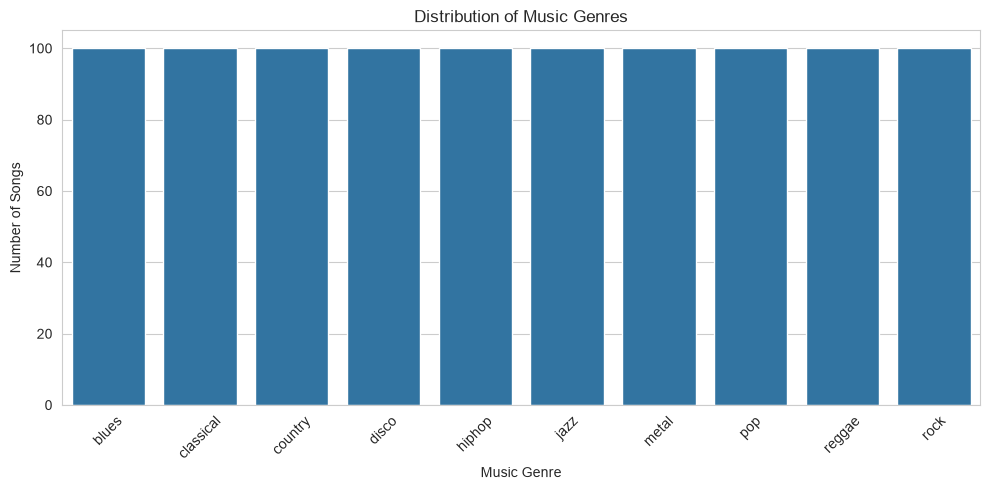

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='label',
    order=sorted(df['label'].unique())
)

plt.title("Distribution of Music Genres")
plt.xlabel("Music Genre")
plt.ylabel("Number of Songs")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

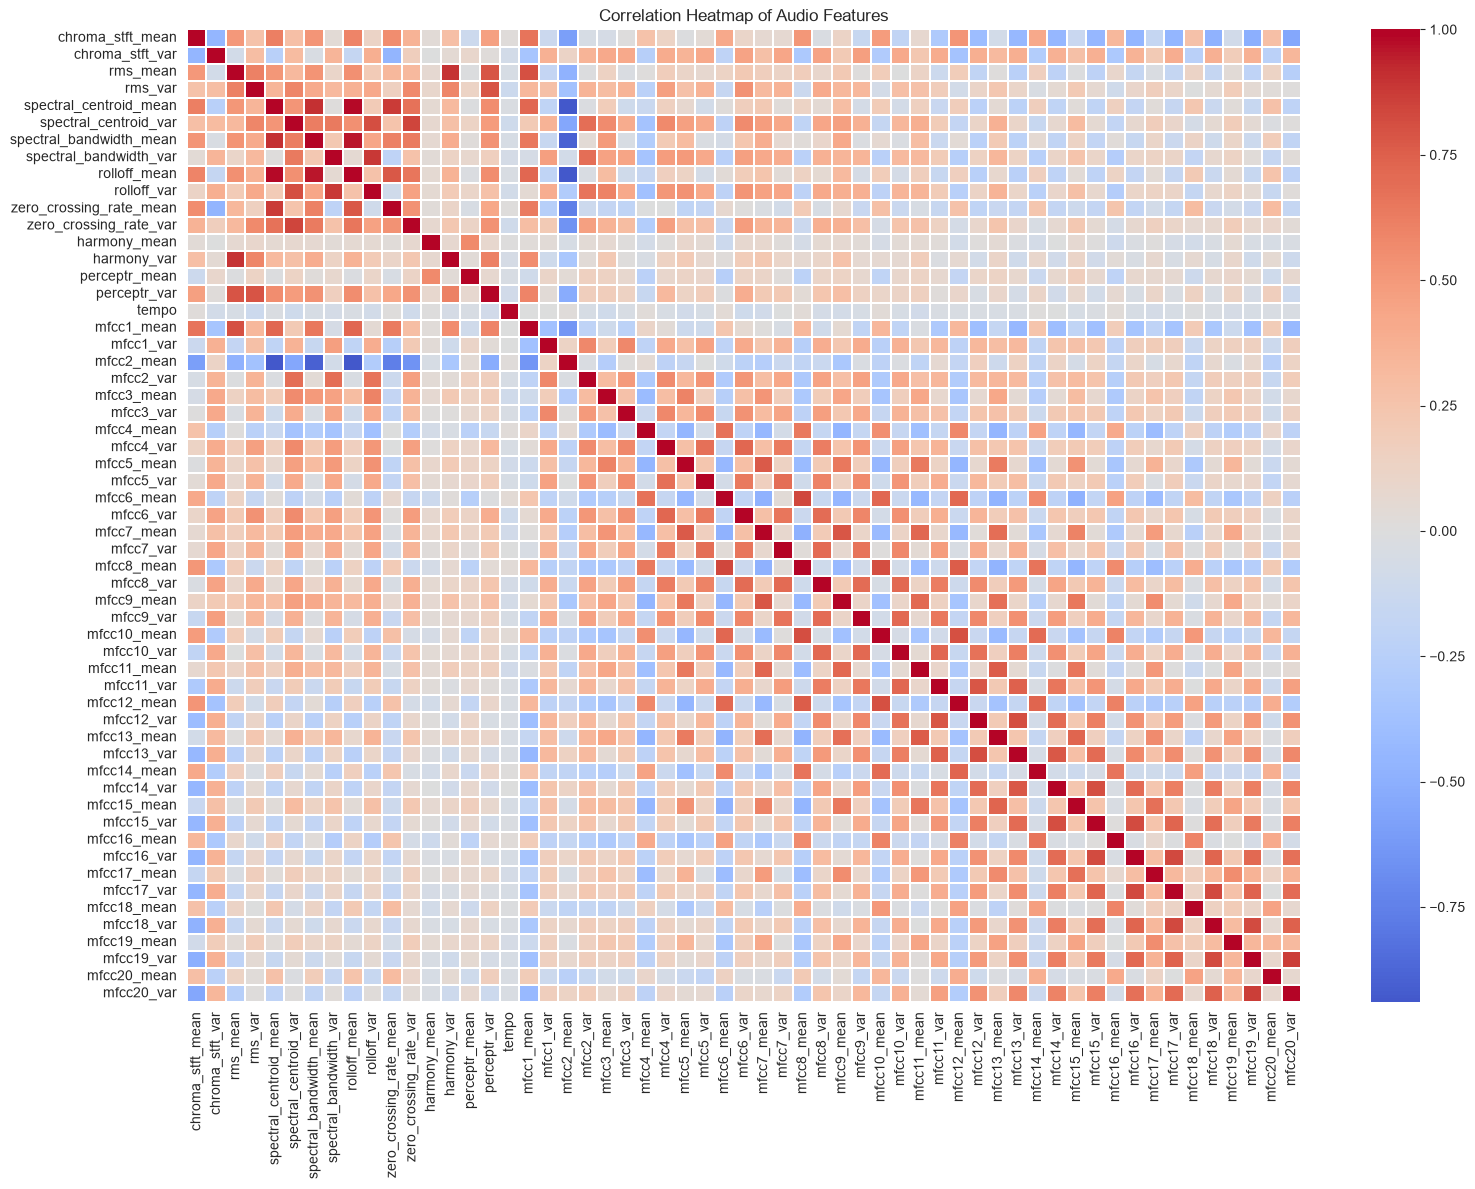

In [ ]:
plt.figure(figsize=(16, 12))

correlation = X.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Audio Features")
plt.tight_layout()
plt.show()

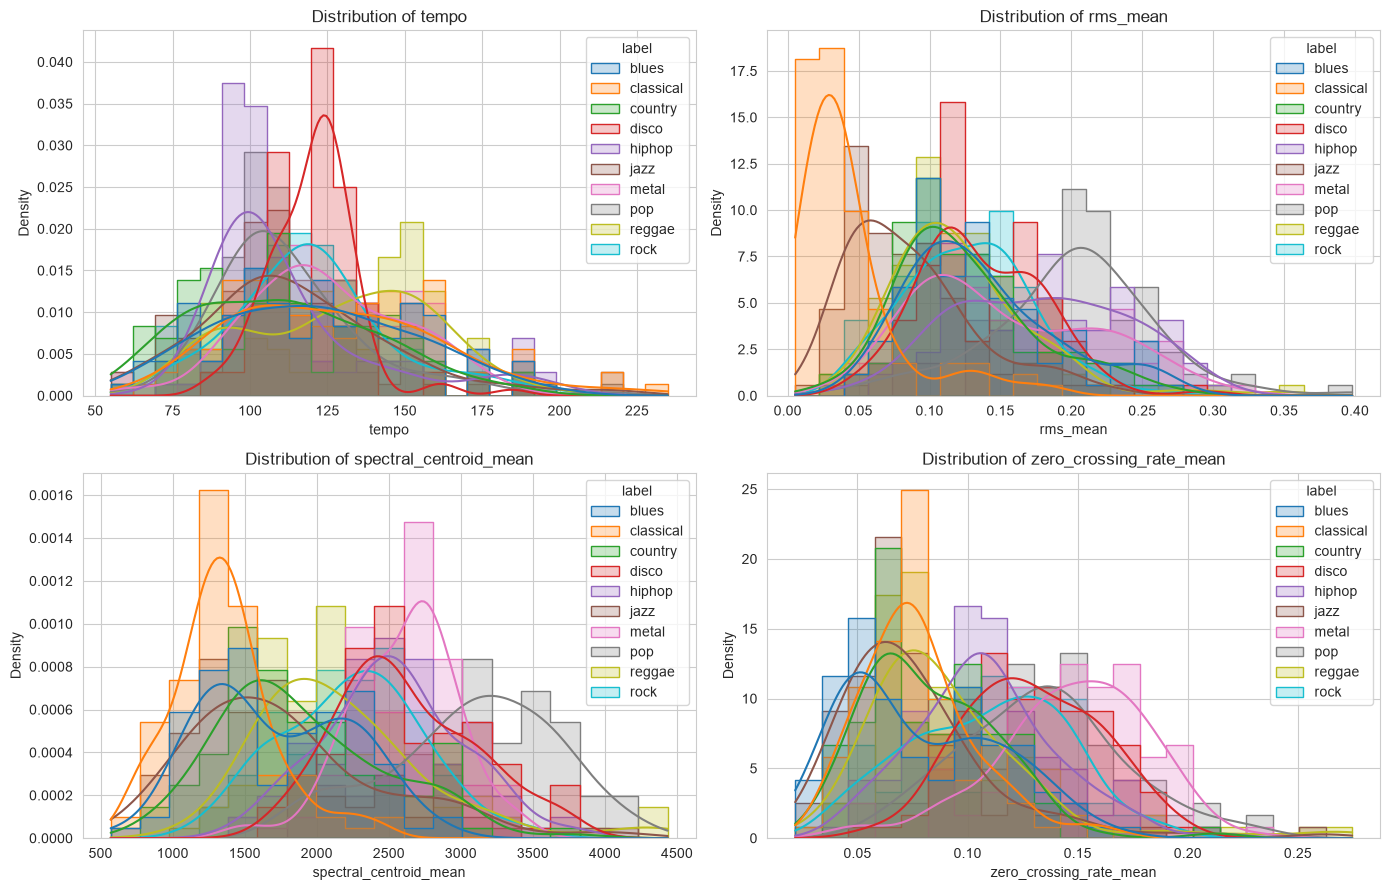

In [ ]:
features = [
    'tempo',
    'rms_mean',
    'spectral_centroid_mean',
    'zero_crossing_rate_mean'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for feature, ax in zip(features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        hue='label',
        kde=True,
        ax=ax,
        element='step',
        stat='density',
        common_norm=False
    )
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

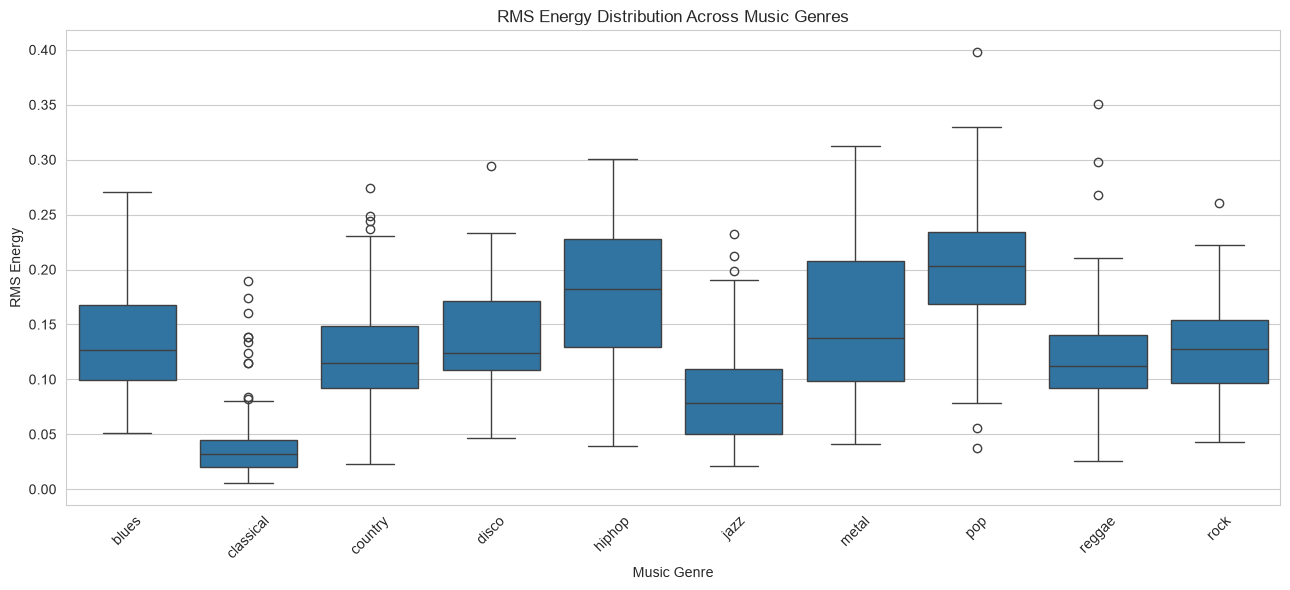

In [ ]:
plt.figure(figsize=(13, 6))

sns.boxplot(data=df, x='label', y='rms_mean')

plt.title("RMS Energy Distribution Across Music Genres")
plt.xlabel("Music Genre")
plt.ylabel("RMS Energy")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

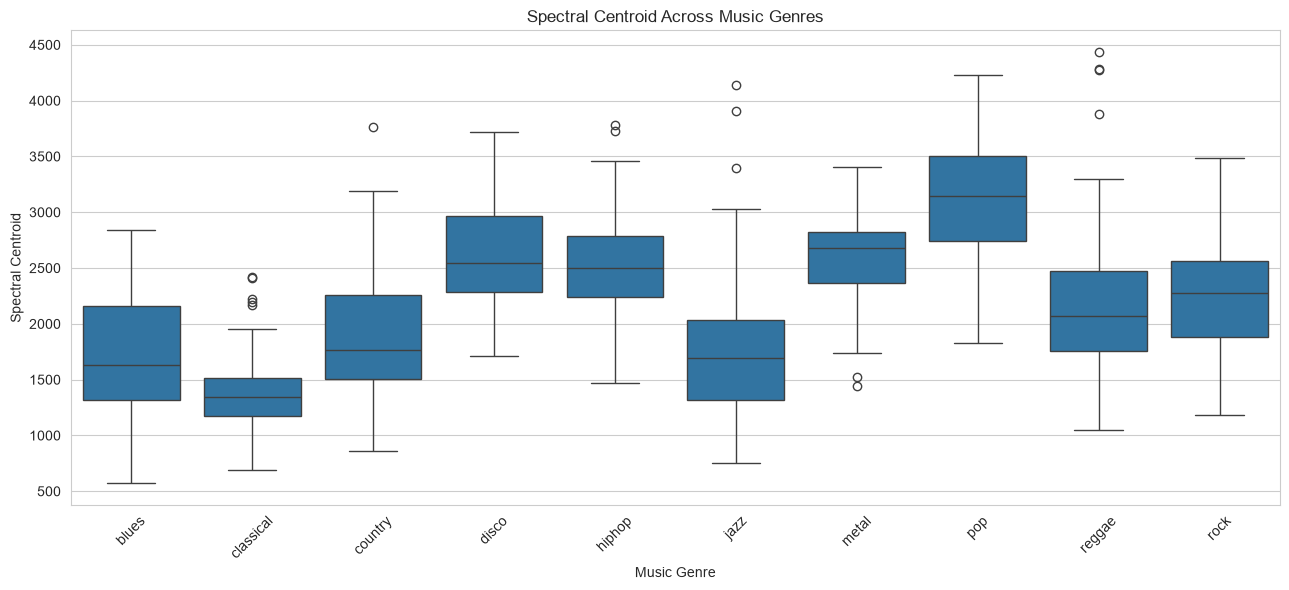

In [ ]:
plt.figure(figsize=(13, 6))

sns.boxplot(data=df, x='label', y='spectral_centroid_mean')

plt.title("Spectral Centroid Across Music Genres")
plt.xlabel("Music Genre")
plt.ylabel("Spectral Centroid")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

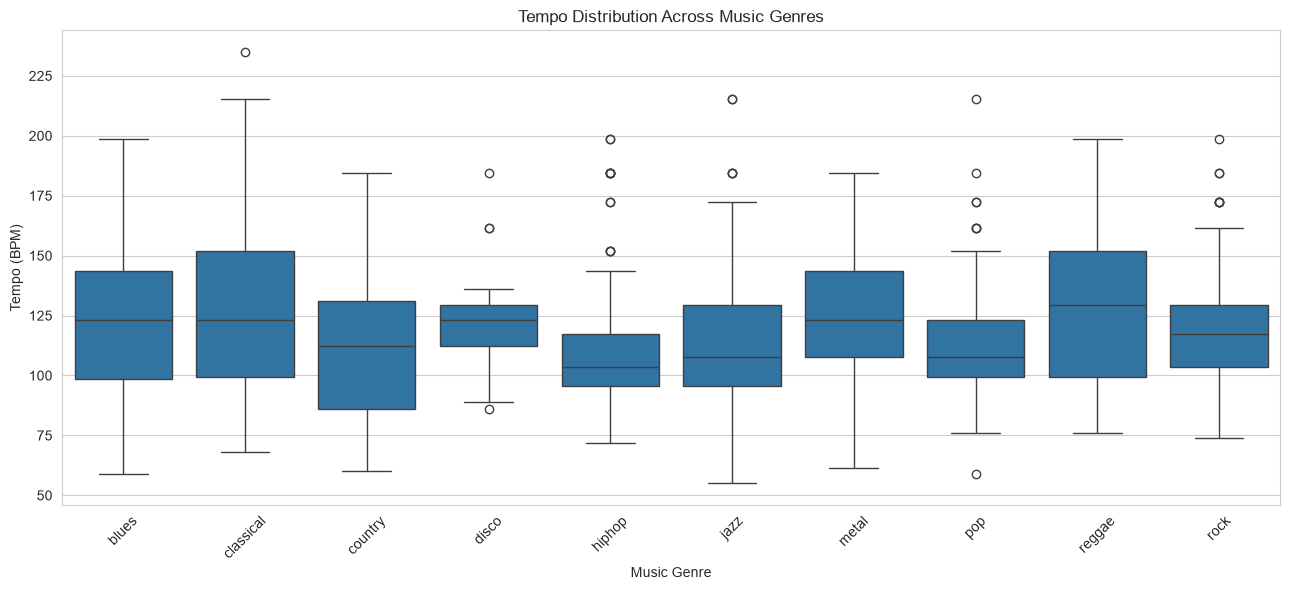

In [ ]:
plt.figure(figsize=(13, 6))

sns.boxplot(data=df, x='label', y='tempo')

plt.title("Tempo Distribution Across Music Genres")
plt.xlabel("Music Genre")
plt.ylabel("Tempo (BPM)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

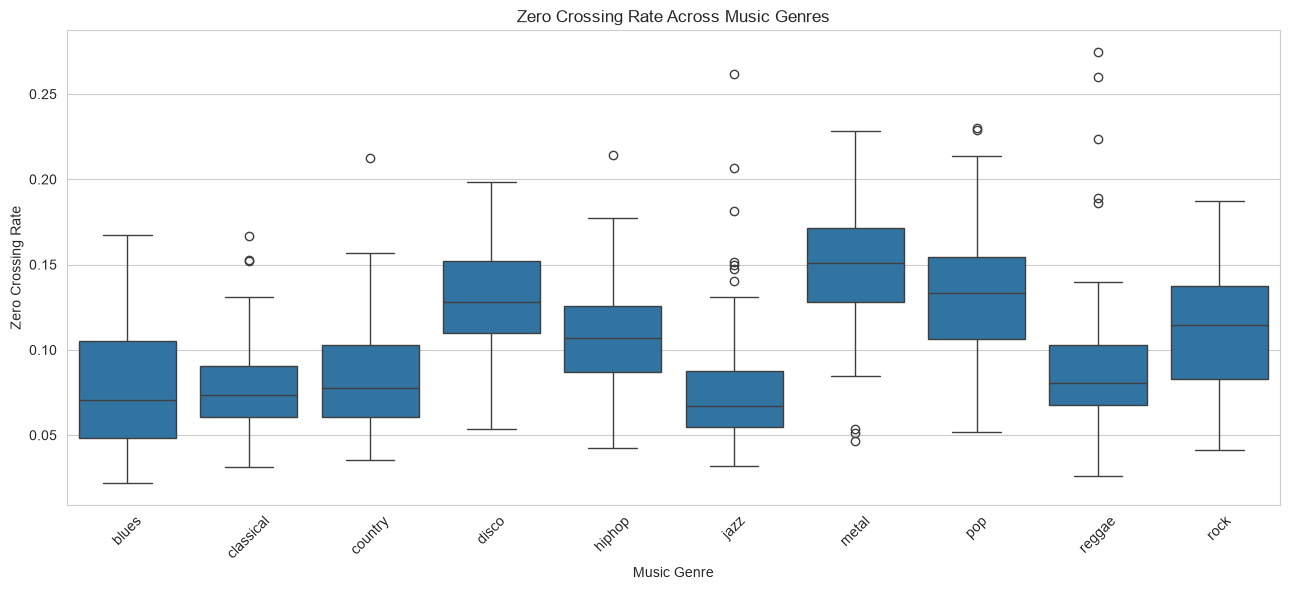

In [ ]:
plt.figure(figsize=(13, 6))

sns.boxplot(data=df, x='label', y='zero_crossing_rate_mean')

plt.title("Zero Crossing Rate Across Music Genres")
plt.xlabel("Music Genre")
plt.ylabel("Zero Crossing Rate")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

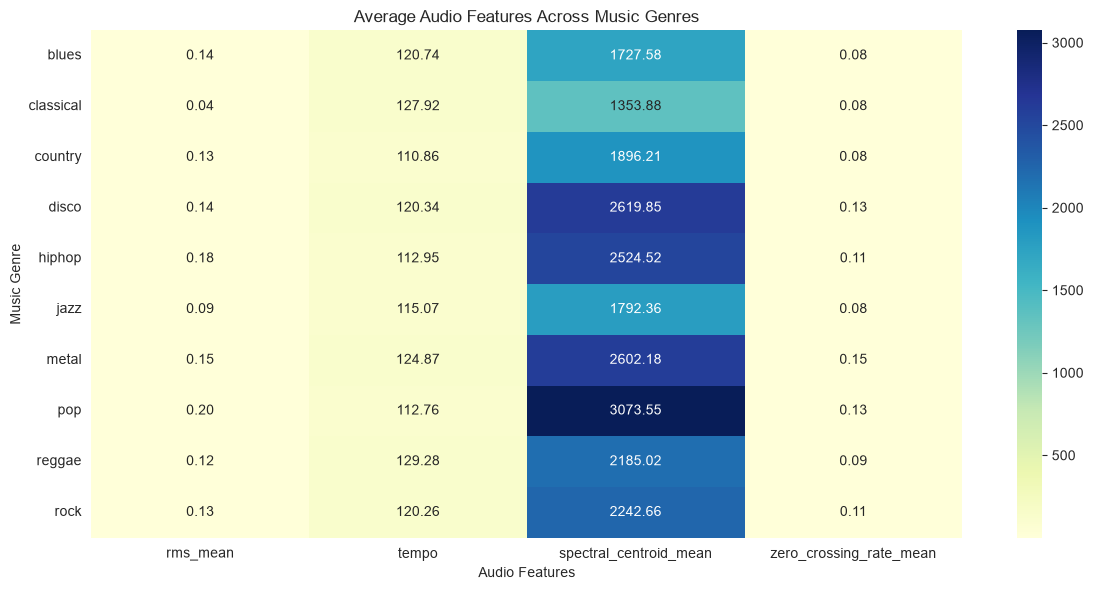

In [ ]:
genre_features = df.groupby('label')[
    ['rms_mean', 'tempo', 'spectral_centroid_mean',
     'zero_crossing_rate_mean']
].mean()

plt.figure(figsize=(12, 6))

sns.heatmap(
    genre_features,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)

plt.title("Average Audio Features Across Music Genres")
plt.xlabel("Audio Features")
plt.ylabel("Music Genre")

plt.tight_layout()
plt.show()

In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nGenre Distribution:")
print(df['label'].value_counts())

print("\nNumber of Audio Features:",
      df.drop(columns=['filename', 'length', 'label']).shape[1])

Dataset Shape: (1000, 60)

Missing Values: 0

Duplicate Rows: 0

Genre Distribution:
label
blues        100
classical    100
country      100
disco        100
hiphop       100
jazz         100
metal        100
pop          100
reggae       100
rock         100
Name: count, dtype: int64

Number of Audio Features: 57


In [ ]:
df = df.drop_duplicates(subset='filename')

X = df.drop(columns=['filename', 'length', 'label'])
y = df['label']

X = X.replace([np.inf, -np.inf], np.nan)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nMusic Genres:")
print(sorted(y.unique()))

print("\nNumber of Genres:", y.nunique())

Features Shape: (1000, 57)
Target Shape: (1000,)

Music Genres:
['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

Number of Genres: 10


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 800
Testing Samples: 200


In [ ]:
print("Training Genre Distribution:")
print(y_train.value_counts())

print("\nTesting Genre Distribution:")
print(y_test.value_counts())

Training Genre Distribution:
label
jazz         80
country      80
rock         80
hiphop       80
pop          80
reggae       80
metal        80
blues        80
classical    80
disco        80
Name: count, dtype: int64

Testing Genre Distribution:
label
classical    20
blues        20
metal        20
jazz         20
country      20
rock         20
hiphop       20
reggae       20
disco        20
pop          20
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Stratified Cross Validation Ready")

5-Fold Stratified Cross Validation Ready


In [ ]:
knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier())
])

knn_params = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    knn_pipeline,
    knn_params,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("KNN Best Parameters:", knn_grid.best_params_)
print("KNN Best CV Score:", knn_grid.best_score_)

KNN Best Parameters: {'classifier__metric': 'manhattan', 'classifier__n_neighbors': 3, 'classifier__weights': 'distance'}
KNN Best CV Score: 0.6962611596501981


In [ ]:
dt_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

dt_params = {
    'classifier__criterion': ['gini', 'entropy'],
    'classifier__max_depth': [5, 10, 15, None],
    'classifier__min_samples_split': [2, 5, 10]
}

dt_grid = GridSearchCV(
    dt_pipeline,
    dt_params,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Decision Tree Best Parameters:", dt_grid.best_params_)
print("Decision Tree Best CV Score:", dt_grid.best_score_)

Decision Tree Best Parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_split': 2}
Decision Tree Best CV Score: 0.49003658028337754


In [ ]:
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

rf_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 20],
    'classifier__min_samples_split': [2, 5]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Random Forest Best Parameters:", rf_grid.best_params_)
print("Random Forest Best CV Score:", rf_grid.best_score_)

Random Forest Best Parameters: {'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Random Forest Best CV Score: 0.6997946646081967


In [ ]:
svm_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', SVC())
])

svm_params = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10]
    },
    {
        'classifier__kernel': ['rbf'],
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 'auto']
    }
]

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("SVM Best Parameters:", svm_grid.best_params_)
print("SVM Best CV Score:", svm_grid.best_score_)

SVM Best Parameters: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
SVM Best CV Score: 0.7480692319432912


In [ ]:
models = {
    'KNN': knn_grid.best_estimator_,
    'Decision Tree': dt_grid.best_estimator_,
    'Random Forest': rf_grid.best_estimator_,
    'SVM': svm_grid.best_estimator_
}

print("All four models are trained successfully!")

All four models are trained successfully!


In [ ]:
results = []
predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    results.append({
        'Algorithm': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

print("Evaluation completed!")


KNN
              precision    recall  f1-score   support

       blues       0.81      0.65      0.72        20
   classical       0.83      0.95      0.88        20
     country       0.61      0.85      0.71        20
       disco       0.44      0.40      0.42        20
      hiphop       0.93      0.65      0.76        20
        jazz       0.88      0.70      0.78        20
       metal       0.81      0.65      0.72        20
         pop       0.67      0.80      0.73        20
      reggae       0.48      0.50      0.49        20
        rock       0.58      0.70      0.64        20

    accuracy                           0.69       200
   macro avg       0.70      0.69      0.69       200
weighted avg       0.70      0.69      0.69       200


Decision Tree
              precision    recall  f1-score   support

       blues       0.50      0.50      0.50        20
   classical       0.79      0.75      0.77        20
     country       0.41      0.65      0.50        20
    

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}'
    })
)

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,SVM,0.7650,0.7689,0.7650,0.7640
1,Random Forest,0.6900,0.6911,0.6900,0.6869
2,KNN,0.6850,0.7032,0.6850,0.6851
3,Decision Tree,0.5250,0.5553,0.5250,0.5276


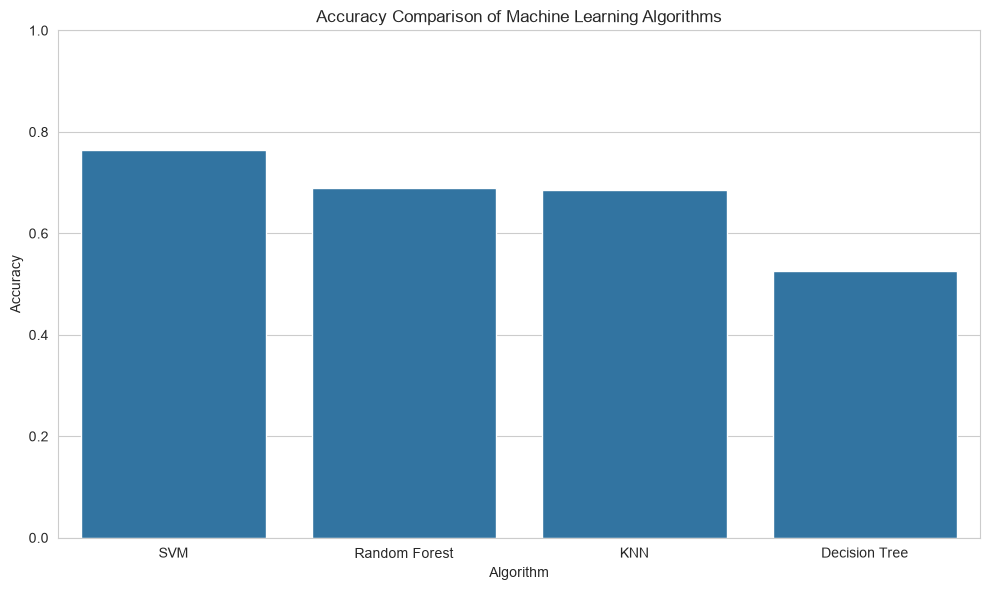

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Accuracy'
)

plt.title("Accuracy Comparison of Machine Learning Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

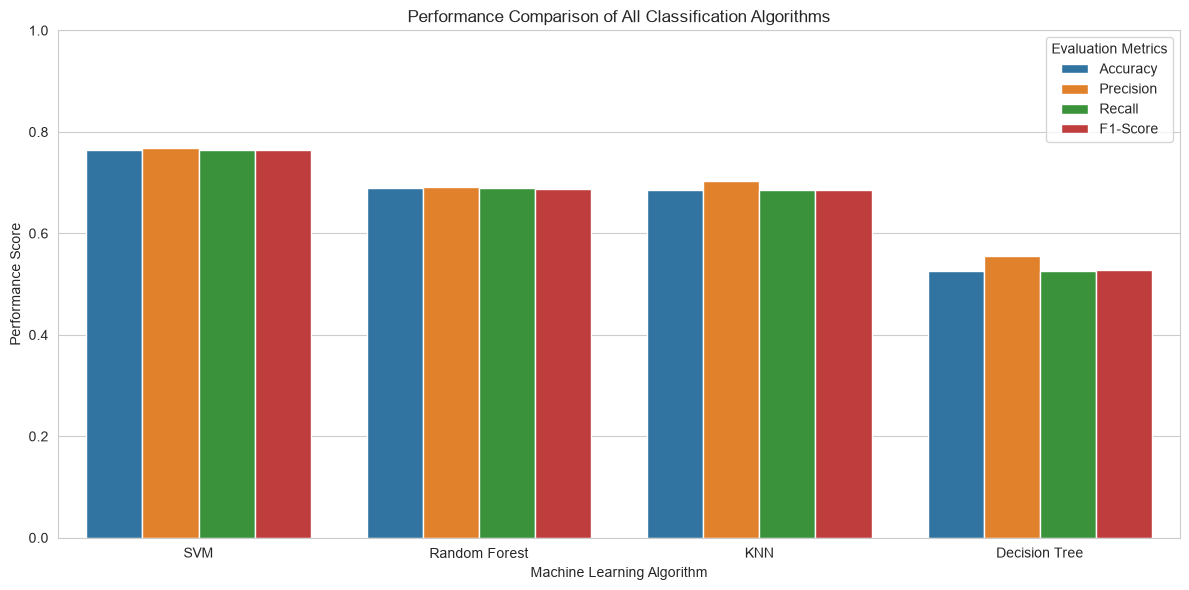

In [ ]:
metrics_df = results_df.melt(
    id_vars='Algorithm',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_df,
    x='Algorithm',
    y='Score',
    hue='Metric'
)

plt.title("Performance Comparison of All Classification Algorithms")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Performance Score")
plt.ylim(0, 1)

plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

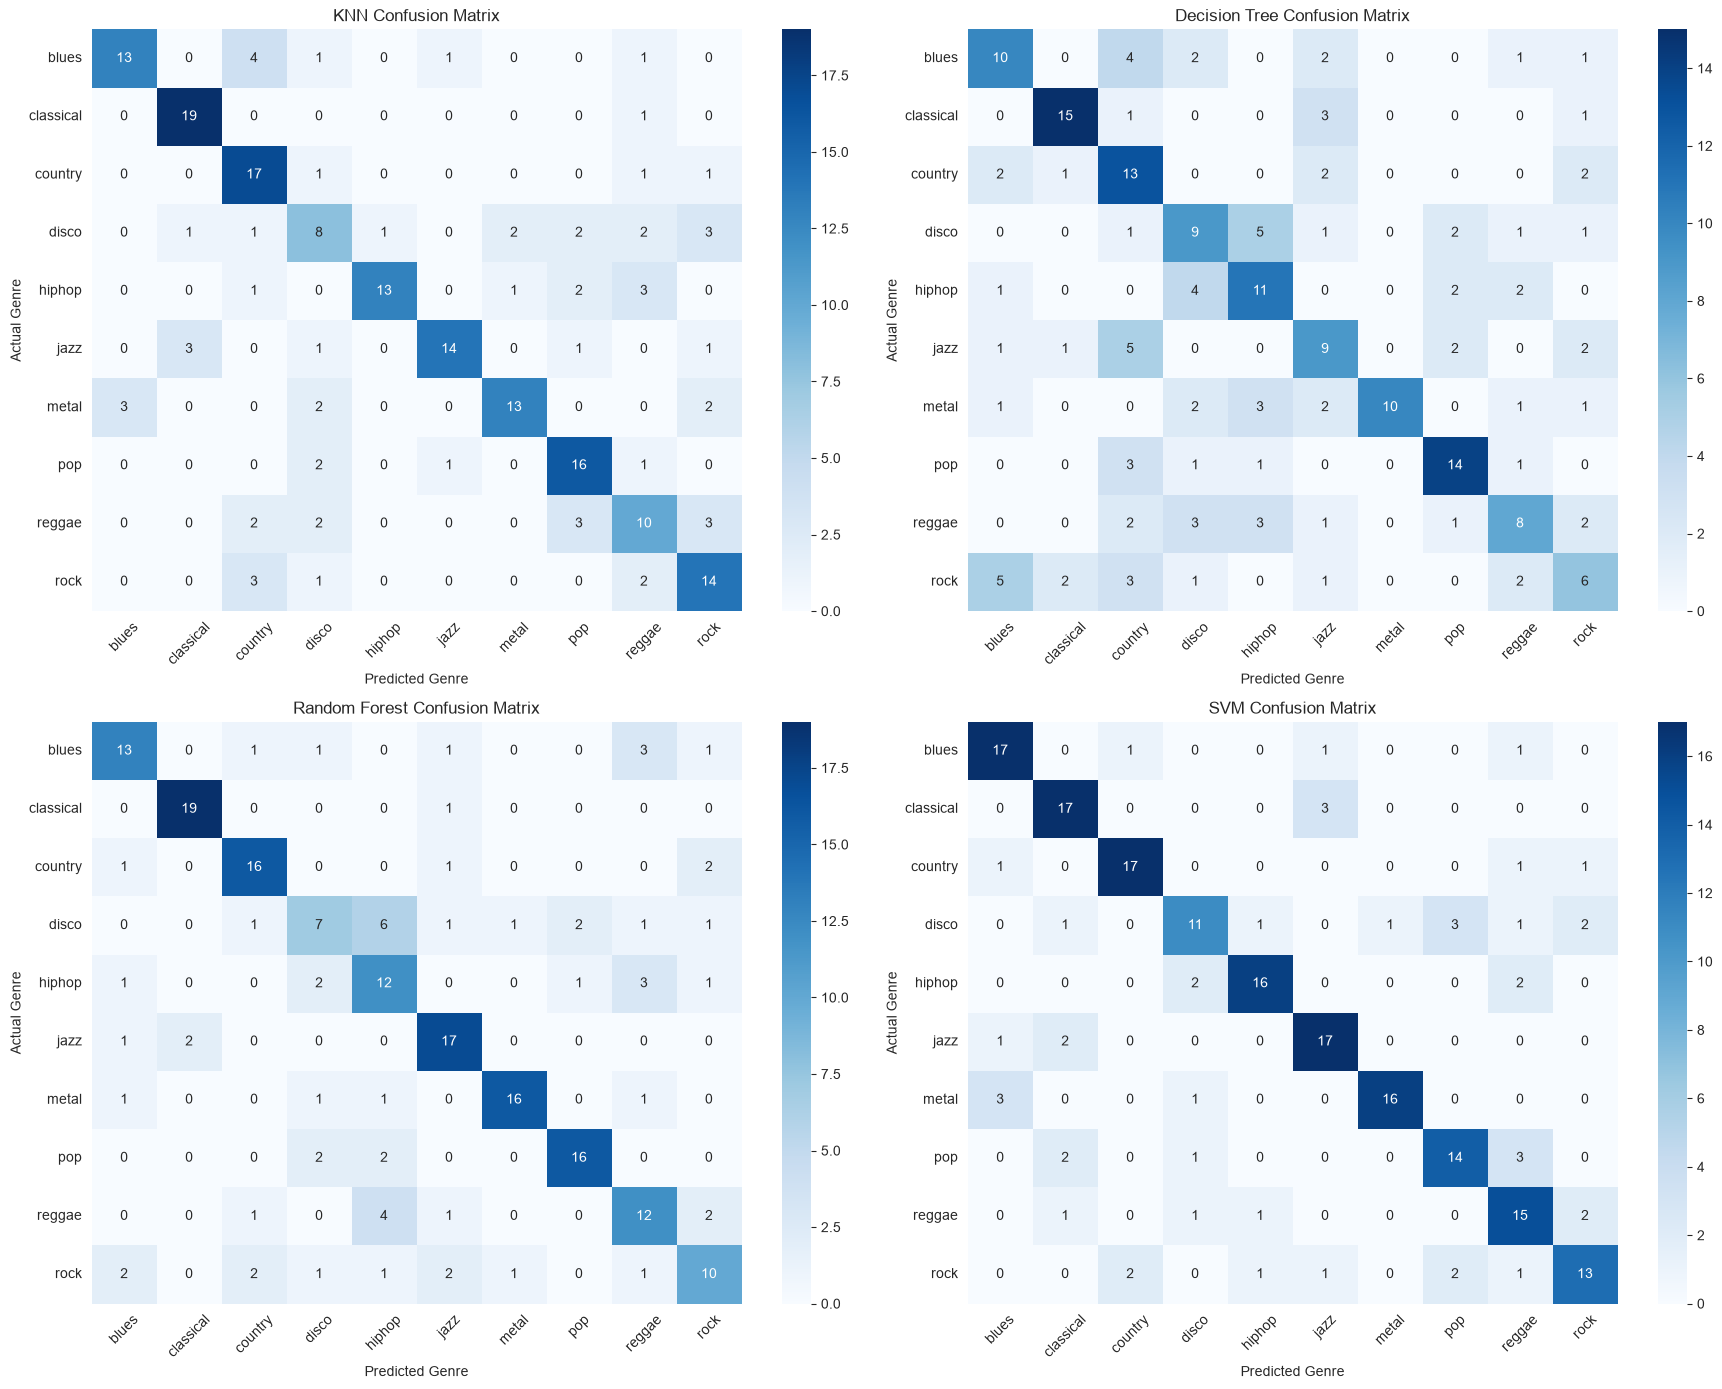

In [ ]:
genres = sorted(y.unique())

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

for (name, y_pred), ax in zip(
    predictions.items(),
    axes.flatten()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=genres
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=genres,
        yticklabels=genres,
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Genre")
    ax.set_ylabel("Actual Genre")

    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
rf_model = rf_grid.best_estimator_

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.named_steps['classifier'].feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

display(importance.head(15))

,Feature,Importance
0,chroma_stft_mean,0.055184
15,perceptr_var,0.044708
23,mfcc4_mean,0.033509
1,chroma_stft_var,0.032129
2,rms_mean,0.030499
3,rms_var,0.030114
6,spectral_bandwidth_mean,0.029720
26,mfcc5_var,0.026251
8,rolloff_mean,0.026141
5,spectral_centroid_var,0.025765


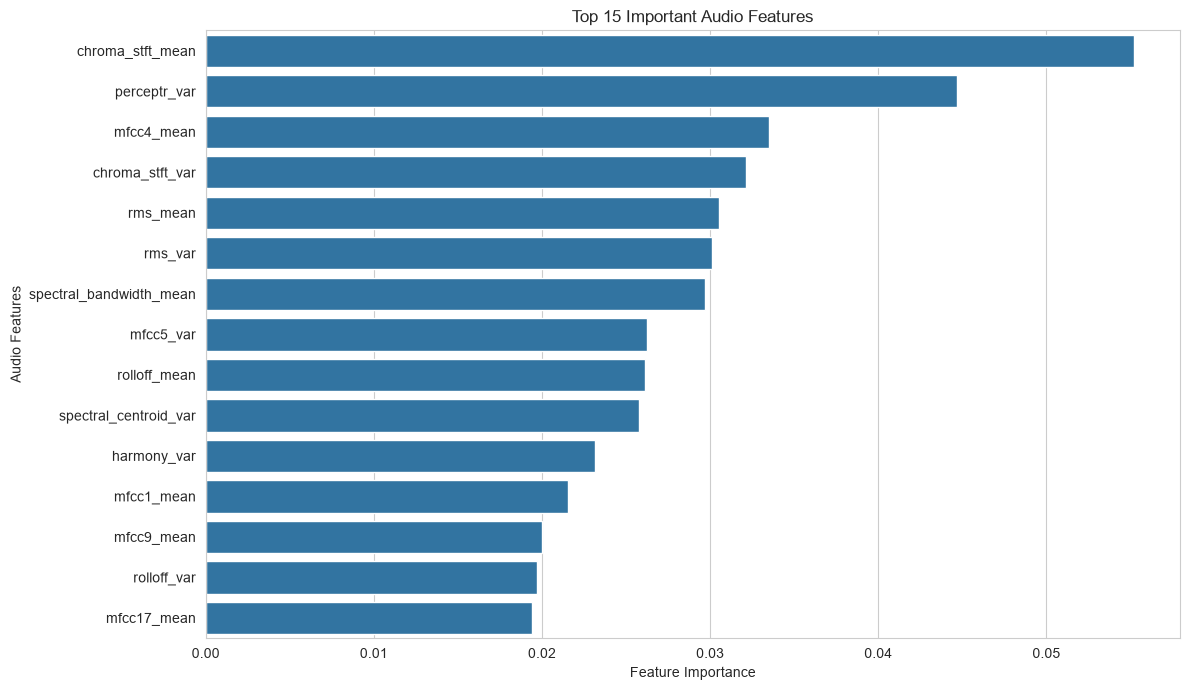

In [ ]:
top_features = importance.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Audio Features")
plt.xlabel("Feature Importance")
plt.ylabel("Audio Features")

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = results_df.iloc[0]['Algorithm']

best_model = models[best_model_name]

print("Best Performing Algorithm:", best_model_name)

print(
    "Best Accuracy:",
    results_df.iloc[0]['Accuracy']
)

print(
    "Best Precision:",
    results_df.iloc[0]['Precision']
)

print(
    "Best Recall:",
    results_df.iloc[0]['Recall']
)

print(
    "Best F1-Score:",
    results_df.iloc[0]['F1-Score']
)

Best Performing Algorithm: SVM
Best Accuracy: 0.765
Best Precision: 0.7689431041468664
Best Recall: 0.765
Best F1-Score: 0.7640211516037709


In [ ]:
import os

os.makedirs("Models", exist_ok=True)
os.makedirs("Results", exist_ok=True)
os.makedirs("Results/Graphs", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [ ]:
import joblib

joblib.dump(
    best_model,
    "Models/best_music_genre_model.pkl"
)

joblib.dump(
    list(X.columns),
    "Models/feature_columns.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!


In [ ]:
results_df.to_csv(
    "Results/model_comparison.csv",
    index=False
)

importance.to_csv(
    "Results/feature_importance.csv",
    index=False
)

print("Results exported successfully!")

Results exported successfully!


In [ ]:
def predict_music_genre(audio_features):

    model = joblib.load(
        "Models/best_music_genre_model.pkl"
    )

    feature_columns = joblib.load(
        "Models/feature_columns.pkl"
    )

    input_data = pd.DataFrame(
        [audio_features],
        columns=feature_columns
    )

    prediction = model.predict(input_data)

    return prediction[0]

In [ ]:
sample_features = X_test.iloc[0].to_dict()

actual_genre = y_test.iloc[0]

predicted_genre = predict_music_genre(sample_features)

print("Actual Music Genre:", actual_genre)

print("Predicted Music Genre:", predicted_genre)

if actual_genre == predicted_genre:
    print("Prediction: Correct")
else:
    print("Prediction: Incorrect")

Actual Music Genre: classical
Predicted Music Genre: classical
Prediction: Correct


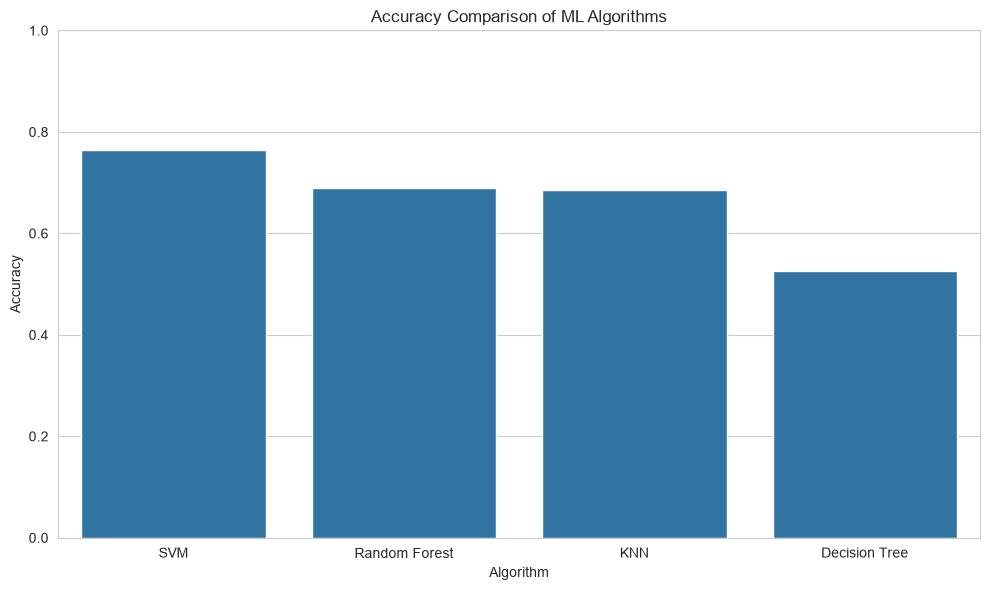

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x='Algorithm',
    y='Accuracy'
)

plt.title("Accuracy Comparison of ML Algorithms")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "Results/Graphs/accuracy_comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

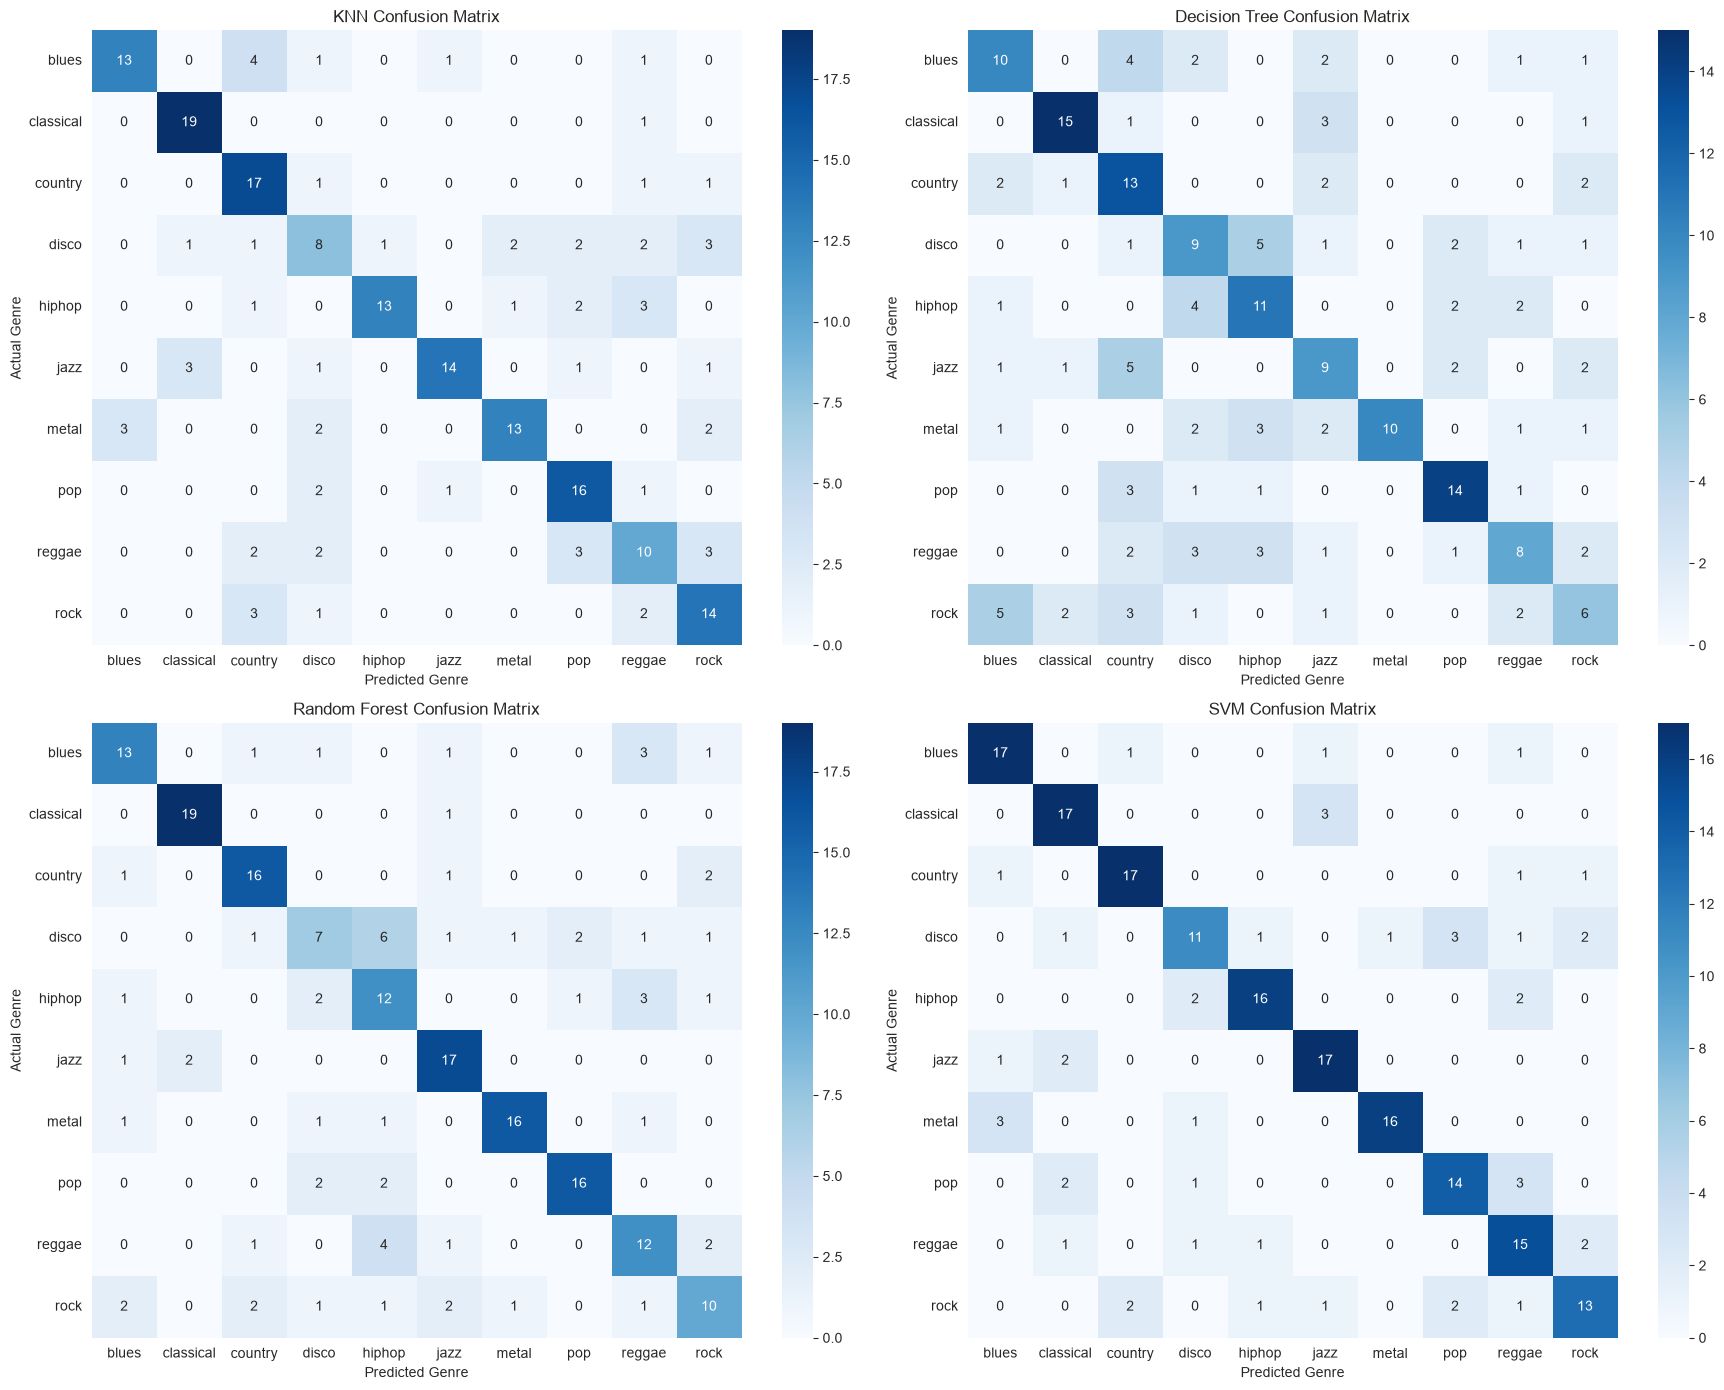

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

for (name, y_pred), ax in zip(
    predictions.items(),
    axes.flatten()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=genres
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=genres,
        yticklabels=genres,
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Genre")
    ax.set_ylabel("Actual Genre")

plt.tight_layout()

plt.savefig(
    "Results/Graphs/confusion_matrices.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

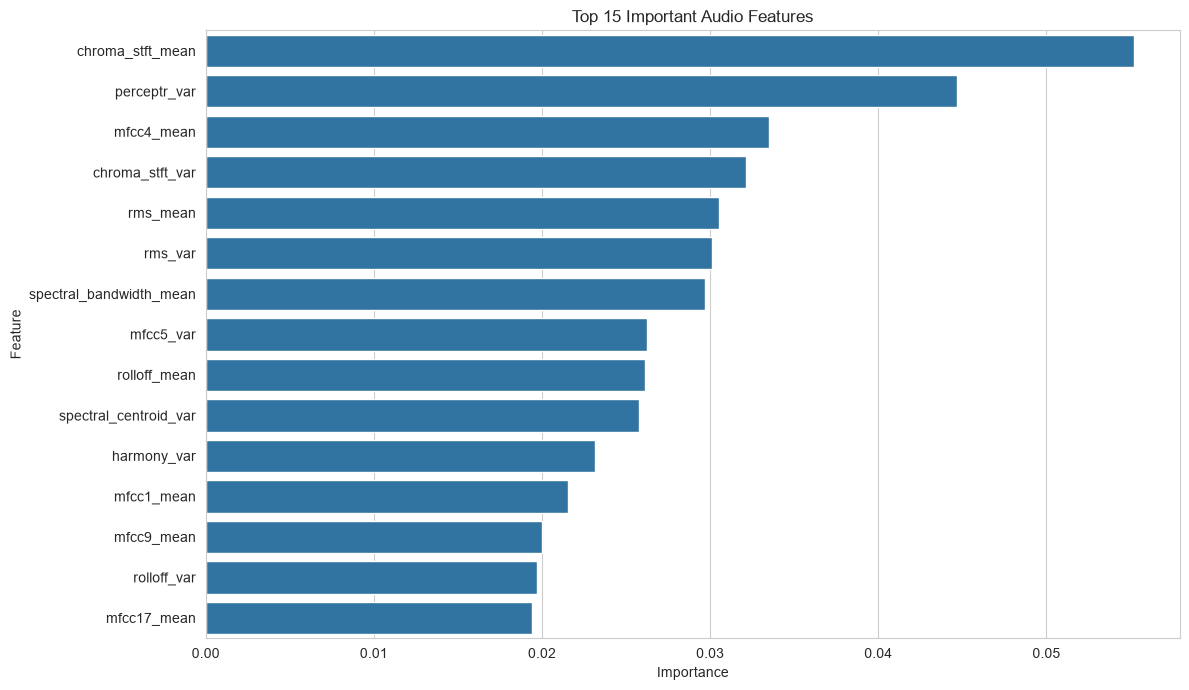

In [ ]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Audio Features")

plt.tight_layout()

plt.savefig(
    "Results/Graphs/feature_importance.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
print("=" * 60)
print("MUSIC GENRE CLASSIFICATION PROJECT")
print("=" * 60)

print("\nDataset Information")
print("Total Songs:", len(df))
print("Total Genres:", y.nunique())
print("Total Audio Features:", X.shape[1])

print("\nModel Performance")
display(results_df)

print("\nBest Performing Model:", best_model_name)

print("\nBest Model Accuracy:",
      round(results_df.iloc[0]['Accuracy'] * 100, 2), "%")

print("Best Model F1-Score:",
      round(results_df.iloc[0]['F1-Score'], 4))

print("\nProject execution completed successfully!")

MUSIC GENRE CLASSIFICATION PROJECT

Dataset Information
Total Songs: 1000
Total Genres: 10
Total Audio Features: 57

Model Performance


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,SVM,0.765,0.768943,0.765,0.764021
1,Random Forest,0.690,0.691141,0.690,0.686874
2,KNN,0.685,0.703244,0.685,0.685148
3,Decision Tree,0.525,0.555331,0.525,0.527583



Best Performing Model: SVM

Best Model Accuracy: 76.5 %
Best Model F1-Score: 0.764

Project execution completed successfully!
